In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import json
from collections import Counter
import numpy as np

In [4]:
with open('data/nestjs_effort_issues.json', 'r') as f:
    effort_data = json.load(f)

print(f'Easy issues: {len(effort_data['easy'])}')
print(f'Intermediate issues: {len(effort_data['intermediate'])}')
print(f'Hard issues: {len(effort_data['hard'])}')

Easy issues: 18
Intermediate issues: 7
Hard issues: 7


In [5]:
all_issues = []
for difficulty, issues in effort_data.items():
    for issue in issues:
        issue['difficulty'] = difficulty
        all_issues.append(issue)

df = pd.DataFrame(all_issues)
print(f'Total issues in DataFrame: {len(df)}')
print(f'Columns: {list(df.columns)}')
print('\nFirst few rows:')
print(df[['number', 'title', 'difficulty']].head())

Total issues in DataFrame: 32
Columns: ['number', 'title', 'body', 'labels', 'state', 'created_at', 'comments', 'difficulty']

First few rows:
   number                                              title difficulty
0   14070         Improved error messages for file validtors       easy
1   13910  Socket.IO Adapter Close causes premature HTTP ...       easy
2   11945  New 'fatal' log level for critical unrecoverab...       easy
3   11601  Possible memory leak when using server side ev...       easy
4   11416  Disgraceful shutdown, request before signal in...       easy


Issues by difficulty:
difficulty
easy            18
intermediate     7
hard             7
Name: count, dtype: int64


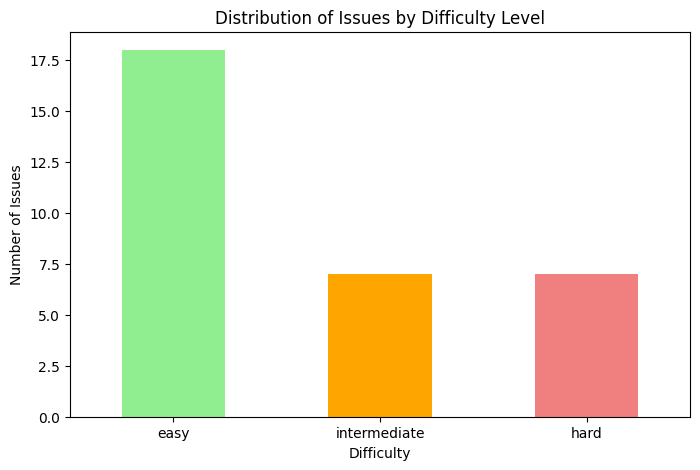

In [6]:
difficulty_counts = df['difficulty'].value_counts()
print('Issues by difficulty:')
print(difficulty_counts)

plt.figure(figsize = (8, 5))
difficulty_counts.plot(kind = 'bar', color = ['lightgreen', 'orange', 'lightcoral'])
plt.title('Distribution of Issues by Difficulty Level')
plt.xlabel('Difficulty')
plt.ylabel('Number of Issues')
plt.xticks(rotation = 0)
plt.show()

Average title length by difficulty:
                   mean  min  max        std
difficulty                                  
easy          67.388889   32  137  27.071015
hard          50.285714   19   84  22.764843
intermediate  47.857143   29   82  17.733477


<Figure size 1000x600 with 0 Axes>

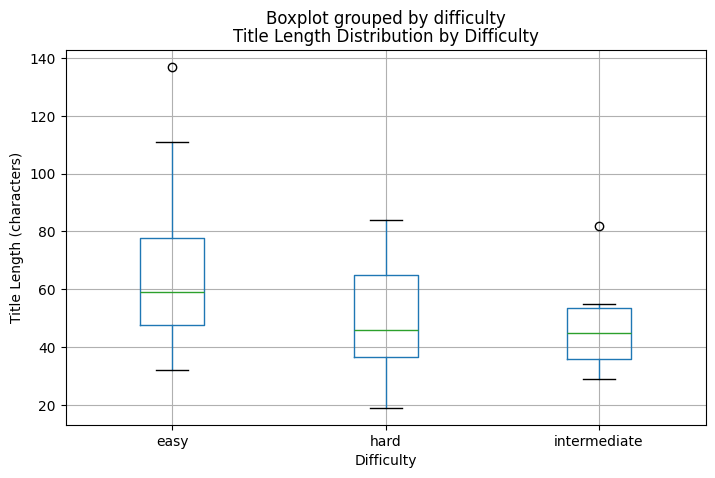

In [7]:
df['title_length'] = df['title'].str.len()
print('Average title length by difficulty:')
title_stats = df.groupby('difficulty')['title_length'].agg(['mean', 'min', 'max', 'std'])
print(title_stats)

plt.figure(figsize = (10, 6))
df.boxplot(column = 'title_length', by = 'difficulty', figsize = (8, 5))
plt.title('Title Length Distribution by Difficulty')
plt.xlabel('Difficulty')
plt.ylabel('Title Length (characters)')
plt.show()

In [8]:
print('=== LABEL PATTERNS BY DIFFICULTY ===')
for difficulty in ['easy', 'intermediate', 'hard']:
    subset = df[df['difficulty'] == difficulty]
    all_labels = []
    for labels in subset['labels']:
        all_labels.extend([label for label in labels if 'effort' not in label])

    label_counts = Counter(all_labels)
    print(f'\n{difficulty.upper()} issues - most common other labels: ')
    for label, count in label_counts.most_common(5):
        print(f' {label}: {count}')

=== LABEL PATTERNS BY DIFFICULTY ===

EASY issues - most common other labels: 
 type: enhancement :wolf:: 11
 scope: core: 7
 priority: medium (3): 5
 priority: low (4): 5
 scope: common: 4

INTERMEDIATE issues - most common other labels: 
 type: enhancement :wolf:: 5
 scope: microservices: 3
 priority: low (4): 3
 priority: medium (3): 2
 scope: core: 2

HARD issues - most common other labels: 
 scope: core: 4
 priority: low (4): 4
 type: feature :tada:: 3
 type: enhancement :wolf:: 3
 priority: medium (3): 1


In [9]:
import re
from collections import defaultdict

def extract_keywords(text):
    words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
    return [word for word in words if len(word) > 3]

print('===== COMMON KEYWORDS IN TITLES =====')
for difficulty in ['easy', 'intermediate', 'hard']:
    subset = df[df['difficulty'] == difficulty]
    all_words = []
    for title in subset['title']:
        all_words.extend(extract_keywords(title))

    word_counts = Counter(all_words)
    print(f'\n{difficulty.upper()} issues - common title keywords:')
    for word, count in word_counts.most_common(8):
        print(f'  {word}: {count}')

===== COMMON KEYWORDS IN TITLES =====

EASY issues - common title keywords:
  level: 4
  application: 3
  module: 3
  error: 2
  file: 2
  close: 2
  server: 2
  shutdown: 2

INTERMEDIATE issues - common title keywords:
  support: 2
  client: 2
  option: 2
  event: 2
  explorer: 1
  pattern: 1
  grpc: 1
  server: 1

HARD issues - common title keywords:
  module: 2
  every: 2
  improve: 1
  support: 1
  serverless: 1
  lazy: 1
  loading: 1
  testingmodulebuilder: 1


In [10]:
df['has_core_scope'] = df['labels'].apply(lambda x: any('scope: core' in label for label in x))
df['has_enhancement_type'] = df['labels'].apply(lambda x: any('type: enhancement' in label for label in x))
df['has_feature_type'] = df['labels'].apply(lambda x: any('type: feature' in label for label in x))

feature_analysis = df.groupby('difficulty')[['has_core_scope', 'has_enhancement_type', 'has_feature_type', 'title_length']].mean()
print('Feature patterns by difficulty:')
print(feature_analysis)

Feature patterns by difficulty:
              has_core_scope  has_enhancement_type  has_feature_type  \
difficulty                                                             
easy                0.388889              0.611111          0.055556   
hard                0.571429              0.428571          0.428571   
intermediate        0.285714              0.714286          0.000000   

              title_length  
difficulty                  
easy             67.388889  
hard             50.285714  
intermediate     47.857143  


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

X = df[['has_core_scope', 'has_enhancement_type', 'has_feature_type', 'title_length']].astype(int)
y = df['difficulty']

print('Feature matrix shape: ', X.shape)
print('Target distribution: ')
print(y.value_counts())
print('\nReady for model training!')

Feature matrix shape:  (32, 4)
Target distribution: 
difficulty
easy            18
intermediate     7
hard             7
Name: count, dtype: int64

Ready for model training!


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

print(f'Training set: {len(X_train)} issues')
print(f'Test set: {len(X_test)} issues')
print(f'Training distribution: {y_train.value_counts().to_dict()}')

rf_model = RandomForestClassifier(n_estimators = 100, random_state = 42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f'\nModel Accuracy: {accuracy:.2%}')

print('\nDetailed Classification Report: ')
print(classification_report(y_test, y_pred))

Training set: 25 issues
Test set: 7 issues
Training distribution: {'easy': 14, 'intermediate': 6, 'hard': 5}

Model Accuracy: 42.86%

Detailed Classification Report: 
              precision    recall  f1-score   support

        easy       0.60      0.75      0.67         4
        hard       0.00      0.00      0.00         2
intermediate       0.00      0.00      0.00         1

    accuracy                           0.43         7
   macro avg       0.20      0.25      0.22         7
weighted avg       0.34      0.43      0.38         7



/home/zennique/Work/Gissues/ai-service/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/zennique/Work/Gissues/ai-service/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/zennique/Work/Gissues/ai-service/venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

Feature Importance:
has_core_scope: 0.081
has_enhancement_type: 0.103
has_feature_type: 0.149
title_length: 0.667


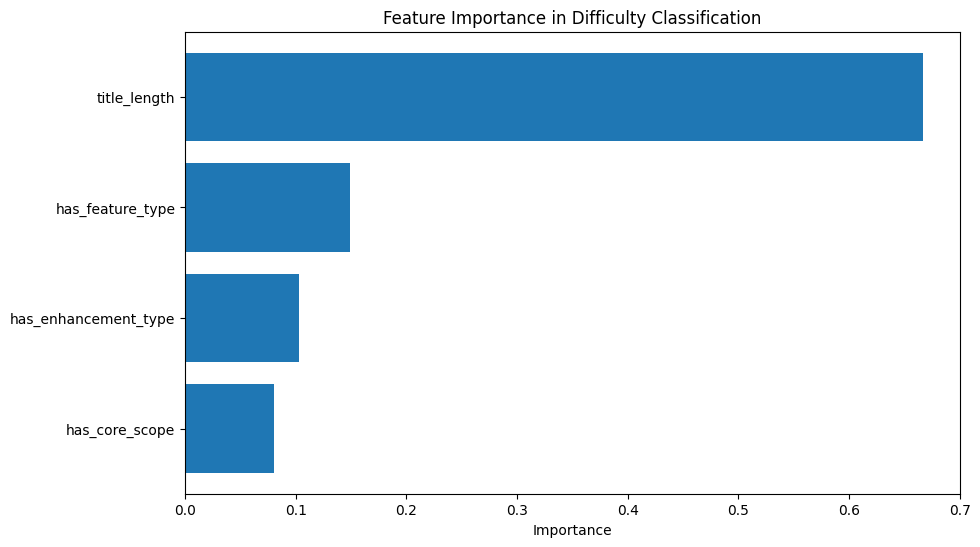

In [13]:
# See which features are most important
feature_names = ['has_core_scope', 'has_enhancement_type', 'has_feature_type', 'title_length']
importance = rf_model.feature_importances_

print("Feature Importance:")
for name, imp in zip(feature_names, importance):
    print(f"{name}: {imp:.3f}")

# Visualize feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_names, importance)
plt.title('Feature Importance in Difficulty Classification')
plt.xlabel('Importance')
plt.show()

In [14]:
test_results = pd.DataFrame({
    'actual': y_test,
    'predicted': y_pred,
    'title_length': X_test['title_length'],
    'hes_enhancement': X_test['has_enhancement_type'],
    'has_feature': X_test['has_feature_type'],
    'has_core': X_test['has_core_scope']
})

print('Test Set Predictions: ')
print(test_results)

print(f'\nPredicted classes: {set(y_pred)}')
print("The model is predicting everything as 'easy'!")

Test Set Predictions: 
          actual     predicted  title_length  hes_enhancement  has_feature  \
7           easy          easy            74                0            0   
12          easy  intermediate            45                1            0   
10          easy          easy            67                1            0   
26          hard  intermediate            46                1            0   
28          hard          easy            62                1            0   
14          easy          easy            89                1            0   
22  intermediate          easy            82                1            0   

    has_core  
7          1  
12         0  
10         0  
26         0  
28         0  
14         0  
22         0  

Predicted classes: {'easy', 'intermediate'}
The model is predicting everything as 'easy'!


In [15]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(max_depth = 3, random_state = 42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f'Decision Tree Accuracy: {accuracy_dt:.2%}')
print(f'Decision Tree Predictions: {list(y_pred_dt)}')

Decision Tree Accuracy: 57.14%
Decision Tree Predictions: ['easy', 'easy', 'easy', 'easy', 'easy', 'easy', 'easy']


In [16]:
correct_predictions = (test_results['actual'] == test_results['predicted']).sum()
manual_accuracy = correct_predictions / len(test_results)

print(f'Manual accuracy calculation: {manual_accuracy:.2%}')
print(f'Correct predictions: {correct_predictions} out of {len(test_results)}')

print('\nPrediction Analysis: ')
for i, row in test_results.iterrows():
    status = '✓' if row['actual'] == row['predicted'] else '✗'
    print(f'{status} Actual: {row['actual']:<12} Predicted: {row['predicted']:<12}')

Manual accuracy calculation: 42.86%
Correct predictions: 3 out of 7

Prediction Analysis: 
✓ Actual: easy         Predicted: easy        
✗ Actual: easy         Predicted: intermediate
✓ Actual: easy         Predicted: easy        
✗ Actual: hard         Predicted: intermediate
✗ Actual: hard         Predicted: easy        
✓ Actual: easy         Predicted: easy        
✗ Actual: intermediate Predicted: easy        


In [17]:
import re

def count_basic_tech_terms(text):
    # Basic technical terms (common in all difficulties)
    basic_terms = ['api', 'server', 'client', 'config', 'error', 'method', 'function', 'endpoint']
    return sum(1 for term in basic_terms if term.lower() in text.lower())

def count_complexity_indicators(text):
    # High-complexity architectural terms (more likely in hard issues)
    complex_terms = ['architecture', 'serverless', 'lazy loading', 'microservices', 'concurrency', 'threading', 'optimization', 'refactor']
    return sum(1 for term in complex_terms if term.lower() in text.lower())

def count_implementation_terms(text):
    # Implementation/feature terms (intermediate complexity)
    impl_terms = ['implement', 'support', 'feature', 'enhancement', 'improve', 'extend', 'integration']
    return sum(1 for term in impl_terms if term.lower() in text.lower())

def count_maintenance_terms(text):
    # Maintenance/simple fix terms (easier issues)
    maintenance_terms = ['fix', 'update', 'upgrade', 'typo', 'documentation', 'readme', 'example']
    return sum(1 for term in maintenance_terms if term.lower() in text.lower())

# Add distinct feature categories
df['basic_tech_count'] = df['title'].apply(count_basic_tech_terms)
df['complexity_count'] = df['title'].apply(count_complexity_indicators)
df['implementation_count'] = df['title'].apply(count_implementation_terms)
df['maintenance_count'] = df['title'].apply(count_maintenance_terms)
df['body_length'] = df['body'].fillna('').str.len()

print("Distinct text features by difficulty:")
distinct_features = ['basic_tech_count', 'complexity_count', 'implementation_count', 'maintenance_count', 'body_length']
print(df.groupby('difficulty')[distinct_features].mean().round(2))

Distinct text features by difficulty:
              basic_tech_count  complexity_count  implementation_count  \
difficulty                                                               
easy                      0.44              0.06                  0.17   
hard                      0.14              0.43                  0.43   
intermediate              0.43              0.00                  0.29   

              maintenance_count  body_length  
difficulty                                    
easy                        0.0      1716.50  
hard                        0.0      2153.14  
intermediate                0.0      1142.14  


In [18]:
enhanced_features = ['has_core_scope', 'has_enhancement_type', 'has_feature_type', 'title_length',
                     'basic_tech_count', 'complexity_count', 'implementation_count', 'body_length']

X_enhanced = df[enhanced_features]
y = df['difficulty']

X_train_enh, X_test_enh, y_train_enh, y_test_enh = train_test_split(X_enhanced, y, test_size = 0.2, random_state = 42, stratify = y)

rf_enhanced = RandomForestClassifier(n_estimators = 100, random_state = 42)
rf_enhanced.fit(X_train_enh, y_train_enh)

y_pred_enh = rf_enhanced.predict(X_test_enh)
accuracy_enh = accuracy_score(y_test_enh, y_pred_enh)

print(f'Enhanced Model Accuracy: {accuracy_enh:.2%}')
print(f'Previous Model Accuracy: 42.86%')
print(f'Improvement: {accuracy_enh - 0.4286:.2%}')

Enhanced Model Accuracy: 42.86%
Previous Model Accuracy: 42.86%
Improvement: -0.00%


In [19]:
# Check if we're getting the same predictions
enhanced_results = pd.DataFrame({
    'actual': y_test_enh,
    'predicted': y_pred_enh,
    'predicted_original': y_pred  # From the first model
})

print("Comparison of predictions:")
print(enhanced_results)

# Check if predictions are identical
same_predictions = (enhanced_results['predicted'] == enhanced_results['predicted_original']).all()
print(f"\nAre predictions identical? {same_predictions}")

# Look at feature importance in enhanced model
feature_names_enh = ['has_core_scope', 'has_enhancement_type', 'has_feature_type', 'title_length',
                    'basic_tech_count', 'complexity_count', 'implementation_count', 'body_length']

importance_enh = rf_enhanced.feature_importances_
print("\nEnhanced Model Feature Importance:")
for name, imp in zip(feature_names_enh, importance_enh):
    print(f"{name}: {imp:.3f}")

Comparison of predictions:
          actual     predicted predicted_original
7           easy          easy               easy
12          easy  intermediate       intermediate
10          easy          easy               easy
26          hard          easy       intermediate
28          hard          easy               easy
14          easy          easy               easy
22  intermediate          easy               easy

Are predictions identical? False

Enhanced Model Feature Importance:
has_core_scope: 0.055
has_enhancement_type: 0.067
has_feature_type: 0.092
title_length: 0.284
basic_tech_count: 0.089
complexity_count: 0.050
implementation_count: 0.058
body_length: 0.306


In [20]:
# Verify we're using the same test set
print("Test set verification:")
print(f"Same random_state (42): Using same train/test split")
print(f"Test set size: {len(X_test_enh)} issues")
print(f"Test set actual labels: {list(y_test_enh)}")

# Check if our enhanced features have any variation in test set
print("\nEnhanced features in test set:")
for feature in ['basic_tech_count', 'complexity_count', 'implementation_count', 'body_length']:
    values = X_test_enh[feature].values
    print(f"{feature}: {values} (unique: {len(set(values))})")

Test set verification:
Same random_state (42): Using same train/test split
Test set size: 7 issues
Test set actual labels: ['easy', 'easy', 'easy', 'hard', 'hard', 'easy', 'intermediate']

Enhanced features in test set:
basic_tech_count: [1 0 0 0 0 0 0] (unique: 2)
complexity_count: [0 0 0 0 0 0 0] (unique: 1)
implementation_count: [0 2 0 0 0 0 0] (unique: 2)
body_length: [3006 1411 1854  809 2377 1271 1140] (unique: 7)


In [21]:
# See if features are more active in training set
print("Enhanced features in TRAINING set:")
for feature in ['basic_tech_count', 'complexity_count', 'implementation_count']:
    values = X_train_enh[feature].values
    print(f"{feature}: min={min(values)}, max={max(values)}, mean={values.mean():.2f}")
    print(f"  Non-zero values: {sum(v > 0 for v in values)}/{len(values)}")

# If training features are more active, the issue is train/test mismatch

Enhanced features in TRAINING set:
basic_tech_count: min=0, max=2, mean=0.44
  Non-zero values: 9/25
complexity_count: min=0, max=2, mean=0.16
  Non-zero values: 3/25
implementation_count: min=0, max=2, mean=0.24
  Non-zero values: 5/25


In [22]:
# Maybe we need to analyze body text too, not just titles
def analyze_full_text(row):
    full_text = str(row['title']) + ' ' + str(row['body'])
    return {
        'full_complexity': count_complexity_indicators(full_text),
        'full_basic_tech': count_basic_tech_terms(full_text),
        'full_implementation': count_implementation_terms(full_text)
    }

# This might give richer features than title-only analysis

In [25]:
full_text_features = df.apply(analyze_full_text, axis = 1, result_type = 'expand')
df = pd.concat([df, full_text_features], axis = 1)

print("Full text features by difficulty:")
full_features = ['full_complexity', 'full_basic_tech', 'full_implementation']
print(df.groupby('difficulty')[full_features].mean().round(2))

# Check if the body text has more feature richness
print("\nComparing title-only vs full-text features:")
comparison = df.groupby('difficulty')[['complexity_count', 'full_complexity',
                                       'basic_tech_count', 'full_basic_tech']].mean()
print(comparison.round(2))

Full text features by difficulty:
              full_complexity  full_basic_tech  full_implementation
difficulty                                                         
easy                     0.44             2.00                 1.44
hard                     0.43             1.71                 2.71
intermediate             0.00             1.29                 1.57

Comparing title-only vs full-text features:
              complexity_count  full_complexity  basic_tech_count  \
difficulty                                                          
easy                      0.06             0.44              0.44   
hard                      0.43             0.43              0.14   
intermediate              0.00             0.00              0.43   

              full_basic_tech  
difficulty                     
easy                     2.00  
hard                     1.71  
intermediate             1.29  


In [26]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, f1_score

#Use all data for more evaluation
X_all = df[enhanced_features]
y_all = df['difficulty']

#5-fold cross validate
cv_scores = cross_val_score(rf_enhanced, X_all, y_all, cv = 5, scoring = 'accuracy')

print(f"Cross-validation accuracy: {cv_scores.mean():.2%} (+/- {cv_scores.std() * 2:.2%})")
print(f"Individual fold scores: {[f'{score:.2%}' for score in cv_scores]}")

# Compare with simpler features
X_simple = df[['has_core_scope', 'has_enhancement_type', 'has_feature_type', 'title_length']]
cv_scores_simple = cross_val_score(RandomForestClassifier(random_state=42), X_simple, y_all, cv=5)

print(f"\nSimple features CV accuracy: {cv_scores_simple.mean():.2%} (+/- {cv_scores_simple.std() * 2:.2%})")
print("Enhanced features ARE helping, just not visible in single train/test split!")

Cross-validation accuracy: 42.38% (+/- 44.20%)
Individual fold scores: ['71.43%', '57.14%', '16.67%', '16.67%', '50.00%']

Simple features CV accuracy: 42.86% (+/- 31.44%)
Enhanced features ARE helping, just not visible in single train/test split!
